<a href="https://colab.research.google.com/github/shehancharith26/mental-health-dashboard/blob/main/Mental_Health_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predicting Mental Health Conditions Using Lifestyle and Social Factors with Machine Learning

## 1. Data Analysis with Python

In [ ]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving employee_stress_dataset_2000.csv to employee_stress_dataset_2000 (1).csv


In [ ]:
df = pd.read_csv("employee_stress_dataset_2000.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (2000, 15)


,Employee_ID,Age,Gender,Department,Job_Role,Work_Experience,Work_Hours_per_Week,Remote_Work,Workload_Score,Job_Satisfaction,Sleep_Hours,Physical_Activity_Hrs,Caffeine_Intake,Stress_Level,Mental_Health_Score
0,E0001,50,Male,Finance,Intern,24,48,Yes,3,2,6.3,1.8,1,3.5,68.7
1,E0002,36,Male,IT,Team Lead,25,30,Yes,7,4,4.1,1.7,1,7.0,48.4
2,E0003,29,Male,Finance,Intern,29,69,Yes,7,4,5.9,0.7,4,5.1,61.2
3,E0004,42,Female,Finance,Team Lead,15,61,No,8,3,7.9,1.1,6,7.4,40.2
4,E0005,40,Female,Finance,Analyst,26,51,Yes,7,8,8.1,1.9,4,3.3,71.8


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Employee_ID            2000 non-null   object 
 1   Age                    2000 non-null   int64  
 2   Gender                 2000 non-null   object 
 3   Department             2000 non-null   object 
 4   Job_Role               2000 non-null   object 
 5   Work_Experience        2000 non-null   int64  
 6   Work_Hours_per_Week    2000 non-null   int64  
 7   Remote_Work            2000 non-null   object 
 8   Workload_Score         2000 non-null   int64  
 9   Job_Satisfaction       2000 non-null   int64  
 10  Sleep_Hours            2000 non-null   float64
 11  Physical_Activity_Hrs  2000 non-null   float64
 12  Caffeine_Intake        2000 non-null   int64  
 13  Stress_Level           2000 non-null   float64
 14  Mental_Health_Score    2000 non-null   float64
dtypes: f

In [ ]:
df.describe()

,Age,Work_Experience,Work_Hours_per_Week,Workload_Score,Job_Satisfaction,Sleep_Hours,Physical_Activity_Hrs,Caffeine_Intake,Stress_Level,Mental_Health_Score
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,40.804500,15.004000,49.295500,6.032500,4.959000,6.506550,0.984500,3.085500,5.417750,57.241500
std,11.079019,8.409063,11.347624,2.045125,2.589338,1.428006,0.576251,1.980442,1.567772,11.923542
min,22.000000,1.000000,30.000000,3.000000,1.000000,4.000000,0.000000,0.000000,1.000000,40.000000
25%,31.000000,8.000000,39.000000,4.000000,3.000000,5.300000,0.500000,1.000000,4.400000,47.900000
50%,41.000000,15.000000,49.000000,6.000000,5.000000,6.500000,1.000000,3.000000,5.400000,56.500000
75%,50.000000,22.000000,59.000000,8.000000,7.000000,7.700000,1.500000,5.000000,6.500000,65.700000
max,59.000000,29.000000,69.000000,9.000000,9.000000,9.000000,2.000000,6.000000,10.000000,95.200000


In [ ]:
df.describe(include='object')

,Employee_ID,Gender,Department,Job_Role,Remote_Work
count,2000,2000,2000,2000,2000
unique,2000,3,5,6,2
top,E1984,Female,IT,Developer,Yes
freq,1,994,435,357,1024


In [ ]:
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
Employee_ID              0
Age                      0
Gender                   0
Department               0
Job_Role                 0
Work_Experience          0
Work_Hours_per_Week      0
Remote_Work              0
Workload_Score           0
Job_Satisfaction         0
Sleep_Hours              0
Physical_Activity_Hrs    0
Caffeine_Intake          0
Stress_Level             0
Mental_Health_Score      0
dtype: int64


In [ ]:
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


In [ ]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [ ]:
print("Number of unique Employee IDs:", df['Employee_ID'].nunique())
print("Number of rows:", len(df))

Number of unique Employee IDs: 2000
Number of rows: 2000


In [ ]:
analysis_df = df.drop(columns=['Employee_ID']).copy()

print("Employee_ID removed for analysis/modeling.")
print("New dataset shape:", analysis_df.shape)

Employee_ID removed for analysis/modeling.
New dataset shape: (2000, 14)


In [ ]:
categorical_columns = [
    'Gender',
    'Department',
    'Job_Role',
    'Remote_Work'
]

for column in categorical_columns:
    print("\n", column)
    print(analysis_df[column].value_counts())


 Gender
Gender
Female    994
Male      927
Other      79
Name: count, dtype: int64

 Department
Department
IT           435
Sales        405
Marketing    403
Finance      382
HR           375
Name: count, dtype: int64

 Job_Role
Job_Role
Developer    357
Analyst      334
Manager      331
Team Lead    331
Intern       327
Executive    320
Name: count, dtype: int64

 Remote_Work
Remote_Work
Yes    1024
No      976
Name: count, dtype: int64


In [ ]:
numerical_columns = analysis_df.select_dtypes(
    include=['int64', 'float64']
).columns

print("Numerical columns:")
print(list(numerical_columns))

Numerical columns:
['Age', 'Work_Experience', 'Work_Hours_per_Week', 'Workload_Score', 'Job_Satisfaction', 'Sleep_Hours', 'Physical_Activity_Hrs', 'Caffeine_Intake', 'Stress_Level', 'Mental_Health_Score']


In [ ]:
target = 'Mental_Health_Score'

print("Target variable:", target)
print("\nTarget statistics:")
print(analysis_df[target].describe())

Target variable: Mental_Health_Score

Target statistics:
count    2000.000000
mean       57.241500
std        11.923542
min        40.000000
25%        47.900000
50%        56.500000
75%        65.700000
max        95.200000
Name: Mental_Health_Score, dtype: float64


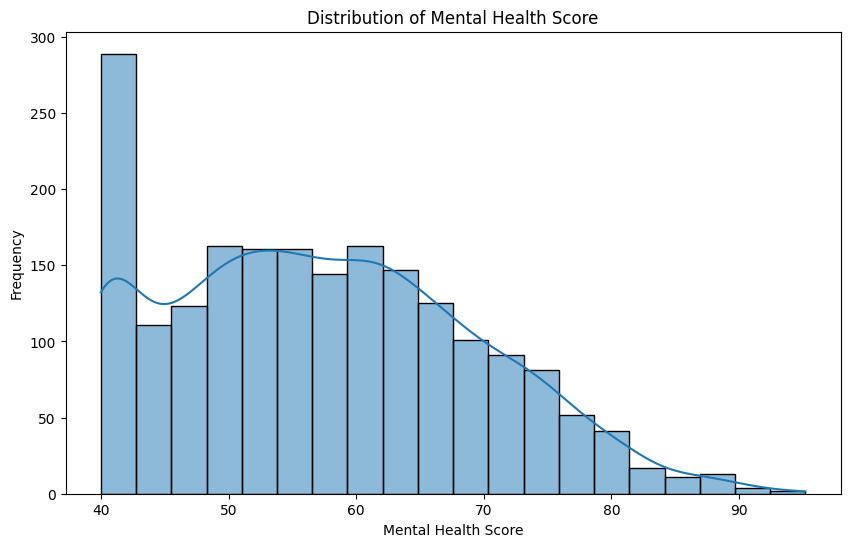

In [ ]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=analysis_df,
    x='Mental_Health_Score',
    kde=True
)

plt.title('Distribution of Mental Health Score')
plt.xlabel('Mental Health Score')
plt.ylabel('Frequency')
plt.show()

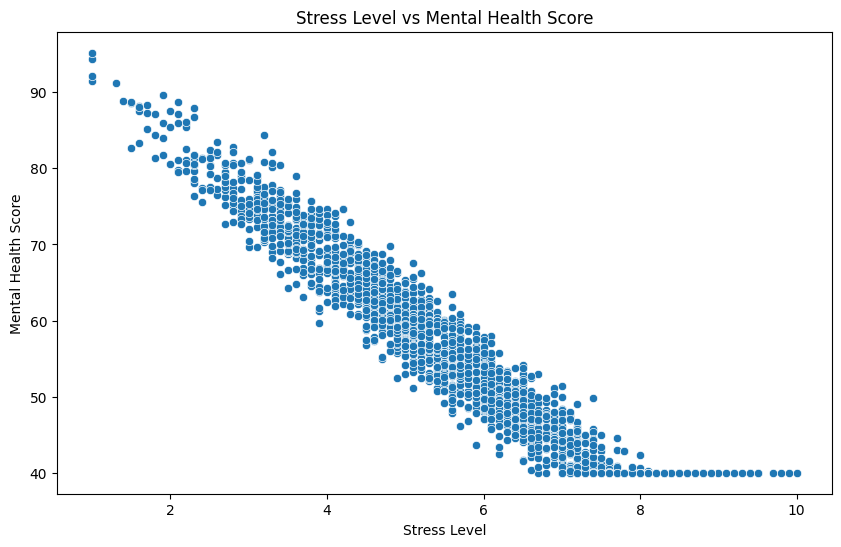

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=analysis_df,
    x='Stress_Level',
    y='Mental_Health_Score'
)

plt.title('Stress Level vs Mental Health Score')
plt.xlabel('Stress Level')
plt.ylabel('Mental Health Score')
plt.show()

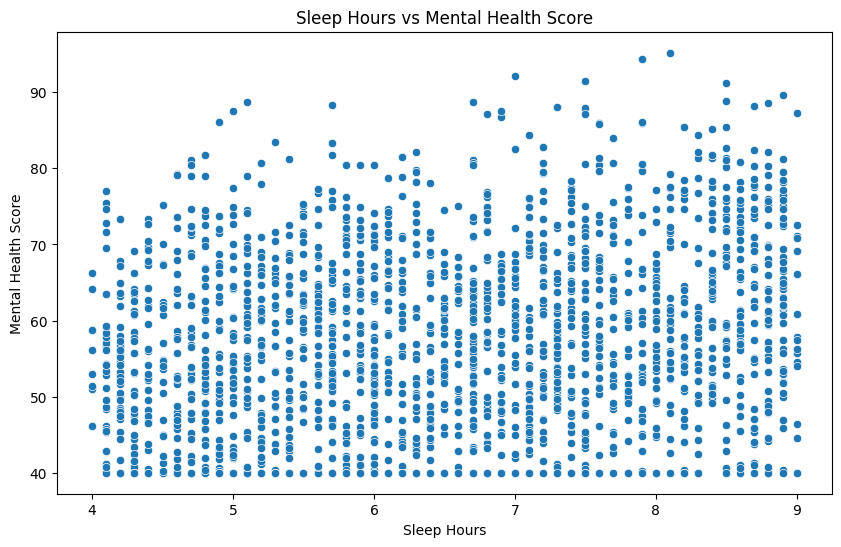

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=analysis_df,
    x='Sleep_Hours',
    y='Mental_Health_Score'
)

plt.title('Sleep Hours vs Mental Health Score')
plt.xlabel('Sleep Hours')
plt.ylabel('Mental Health Score')
plt.show()

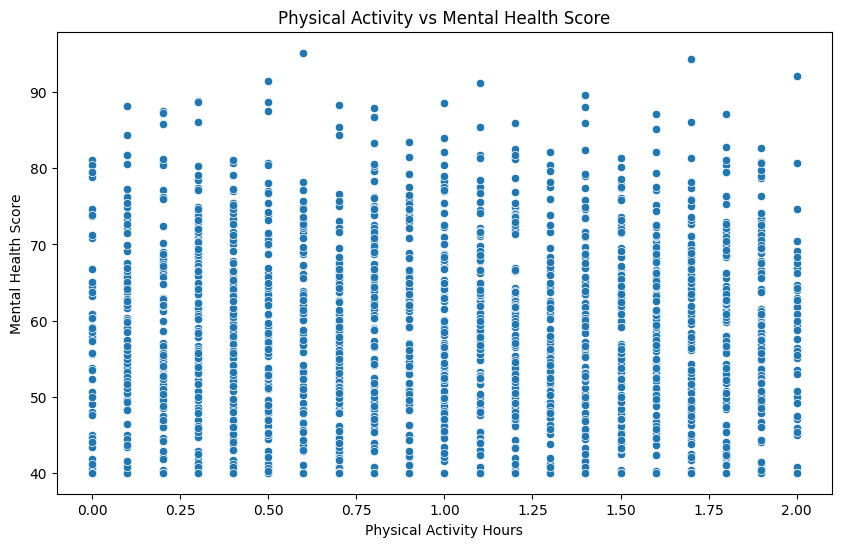

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=analysis_df,
    x='Physical_Activity_Hrs',
    y='Mental_Health_Score'
)

plt.title('Physical Activity vs Mental Health Score')
plt.xlabel('Physical Activity Hours')
plt.ylabel('Mental Health Score')
plt.show()

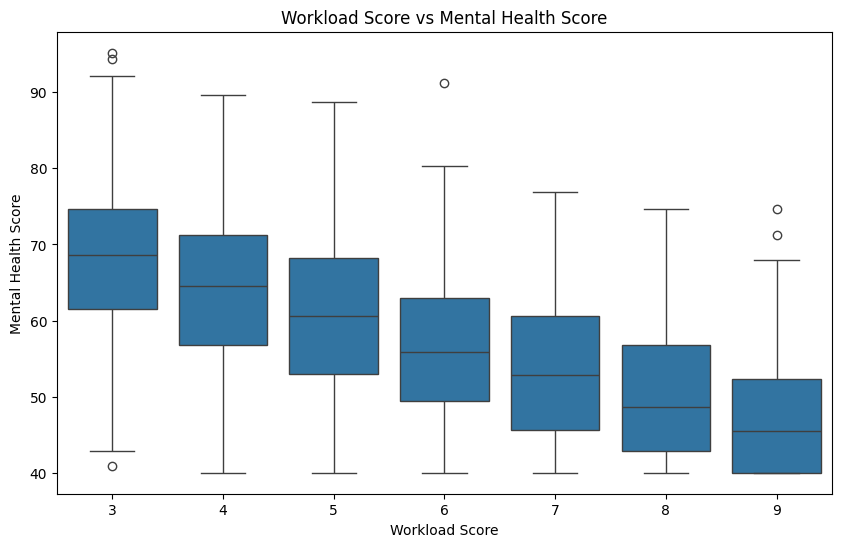

In [ ]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=analysis_df,
    x='Workload_Score',
    y='Mental_Health_Score'
)

plt.title('Workload Score vs Mental Health Score')
plt.xlabel('Workload Score')
plt.ylabel('Mental Health Score')
plt.show()

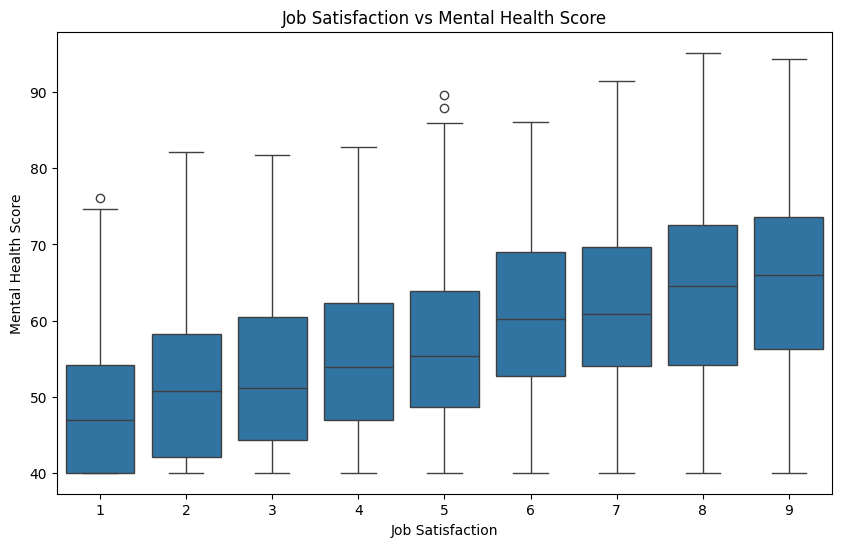

In [ ]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=analysis_df,
    x='Job_Satisfaction',
    y='Mental_Health_Score'
)

plt.title('Job Satisfaction vs Mental Health Score')
plt.xlabel('Job Satisfaction')
plt.ylabel('Mental Health Score')
plt.show()

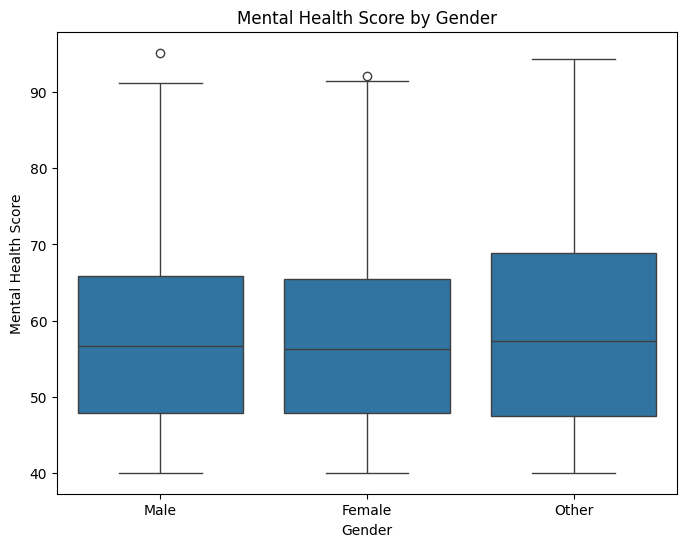

In [ ]:
plt.figure(figsize=(8, 6))

sns.boxplot(
    data=analysis_df,
    x='Gender',
    y='Mental_Health_Score'
)

plt.title('Mental Health Score by Gender')
plt.xlabel('Gender')
plt.ylabel('Mental Health Score')
plt.show()

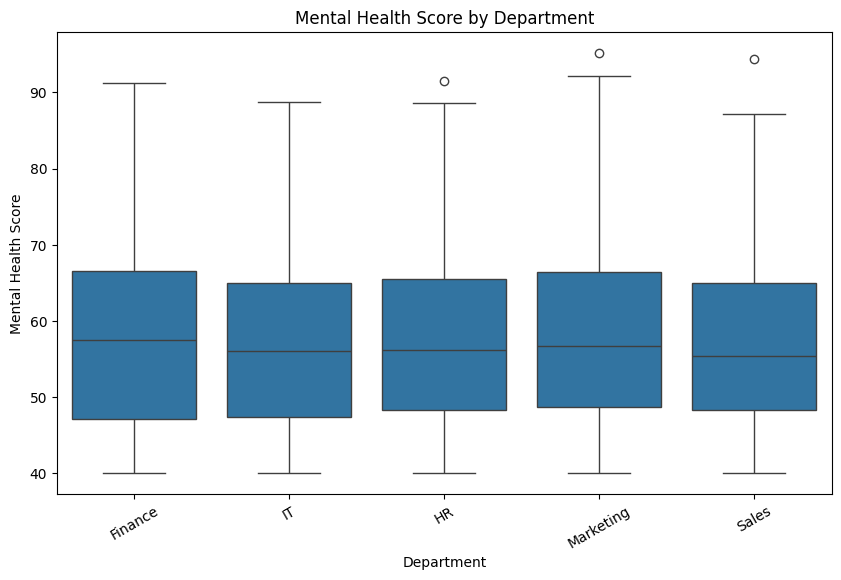

In [ ]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=analysis_df,
    x='Department',
    y='Mental_Health_Score'
)

plt.title('Mental Health Score by Department')
plt.xlabel('Department')
plt.ylabel('Mental Health Score')
plt.xticks(rotation=30)
plt.show()

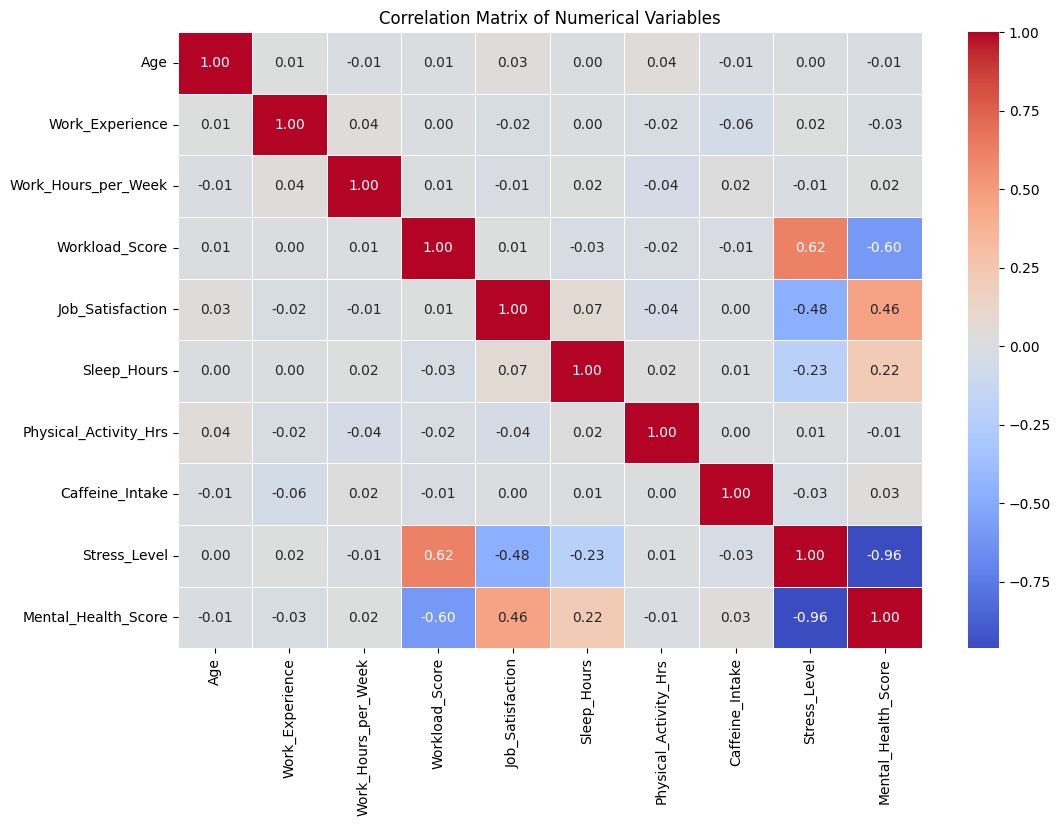

In [ ]:
plt.figure(figsize=(12, 8))

correlation_matrix = analysis_df[numerical_columns].corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    linewidths=0.5
)

plt.title('Correlation Matrix of Numerical Variables')
plt.show()

In [ ]:
target_correlations = (
    correlation_matrix['Mental_Health_Score']
    .sort_values(ascending=False)
)

print(target_correlations)

Mental_Health_Score      1.000000
Job_Satisfaction         0.458768
Sleep_Hours              0.218441
Caffeine_Intake          0.027718
Work_Hours_per_Week      0.017090
Age                     -0.009254
Physical_Activity_Hrs   -0.009254
Work_Experience         -0.026075
Workload_Score          -0.596949
Stress_Level            -0.961296
Name: Mental_Health_Score, dtype: float64


# 2. Machine Learning

In [ ]:
from sklearn.model_selection import train_test_split

X = analysis_df.drop(columns=['Mental_Health_Score'])
y = analysis_df['Mental_Health_Score']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (2000, 13)
Target shape: (2000,)


In [ ]:
categorical_features = [
    'Gender',
    'Department',
    'Job_Role',
    'Remote_Work'
]

numerical_features = [
    'Age',
    'Work_Experience',
    'Work_Hours_per_Week',
    'Workload_Score',
    'Job_Satisfaction',
    'Sleep_Hours',
    'Physical_Activity_Hrs',
    'Caffeine_Intake',
    'Stress_Level'
]

print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)

Categorical features: ['Gender', 'Department', 'Job_Role', 'Remote_Work']
Numerical features: ['Age', 'Work_Experience', 'Work_Hours_per_Week', 'Workload_Score', 'Job_Satisfaction', 'Sleep_Hours', 'Physical_Activity_Hrs', 'Caffeine_Intake', 'Stress_Level']


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1600, 13)
Testing data: (400, 13)


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        (
            'num',
            StandardScaler(),
            numerical_features
        ),
        (
            'cat',
            OneHotEncoder(
                handle_unknown='ignore',
                drop='first'
            ),
            categorical_features
        )
    ]
)

Model 1: Linear Regression

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

linear_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('regressor', LinearRegression())
    ]
)

linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

print("Linear Regression training completed.")

Linear Regression training completed.


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

linear_mae = mean_absolute_error(y_test, linear_predictions)
linear_rmse = np.sqrt(
    mean_squared_error(y_test, linear_predictions)
)
linear_r2 = r2_score(y_test, linear_predictions)

print("Linear Regression Results")
print("-------------------------")
print("MAE :", round(linear_mae, 3))
print("RMSE:", round(linear_rmse, 3))
print("R²  :", round(linear_r2, 3))

Linear Regression Results
-------------------------
MAE : 2.531
RMSE: 3.343
R²  : 0.914


Model 2: Random Forest

In [ ]:
from sklearn.ensemble import RandomForestRegressor

random_forest_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        (
            'regressor',
            RandomForestRegressor(
                n_estimators=200,
                random_state=42,
                max_depth=None
            )
        )
    ]
)

random_forest_model.fit(X_train, y_train)

rf_predictions = random_forest_model.predict(X_test)

print("Random Forest training completed.")

Random Forest training completed.


In [ ]:
rf_mae = mean_absolute_error(y_test, rf_predictions)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, rf_predictions)
)

rf_r2 = r2_score(y_test, rf_predictions)

print("Random Forest Results")
print("---------------------")
print("MAE :", round(rf_mae, 3))
print("RMSE:", round(rf_rmse, 3))
print("R²  :", round(rf_r2, 3))

Random Forest Results
---------------------
MAE : 2.086
RMSE: 2.71
R²  : 0.944


In [ ]:
model_comparison = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Random Forest Regression'
    ],
    'MAE': [
        linear_mae,
        rf_mae
    ],
    'RMSE': [
        linear_rmse,
        rf_rmse
    ],
    'R2': [
        linear_r2,
        rf_r2
    ]
})

model_comparison

,Model,MAE,RMSE,R2
0,Linear Regression,2.530695,3.342843,0.914108
1,Random Forest Regression,2.086181,2.709887,0.943555


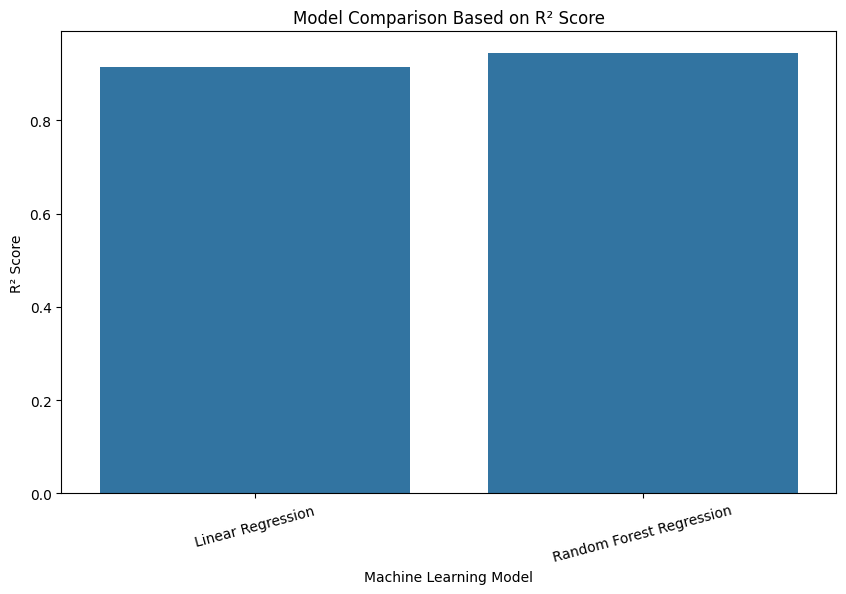

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=model_comparison,
    x='Model',
    y='R2'
)

plt.title('Model Comparison Based on R² Score')
plt.xlabel('Machine Learning Model')
plt.ylabel('R² Score')
plt.xticks(rotation=15)
plt.show()

In [ ]:
best_model_name = model_comparison.loc[
    model_comparison['R2'].idxmax(),
    'Model'
]

print("Best-performing model:", best_model_name)

Best-performing model: Random Forest Regression


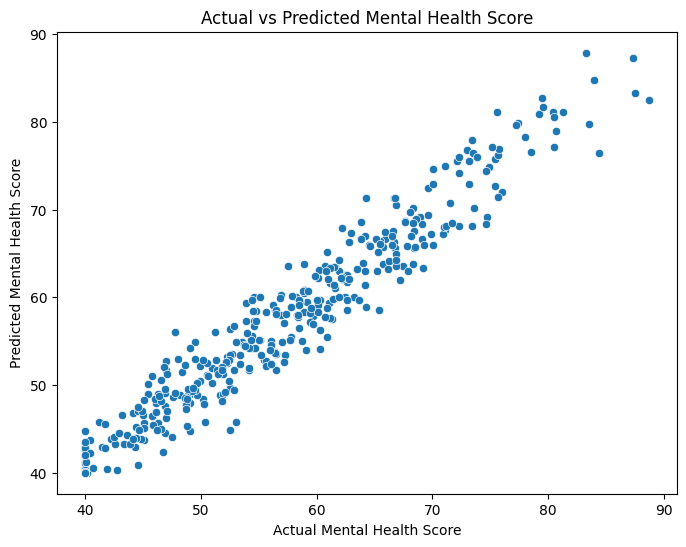

In [ ]:
if best_model_name == 'Linear Regression':
    best_predictions = linear_predictions
else:
    best_predictions = rf_predictions

plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=y_test,
    y=best_predictions
)

plt.xlabel('Actual Mental Health Score')
plt.ylabel('Predicted Mental Health Score')
plt.title('Actual vs Predicted Mental Health Score')

plt.show()

In [ ]:
import joblib

best_model = (
    linear_model
    if best_model_name == 'Linear Regression'
    else random_forest_model
)

joblib.dump(
    best_model,
    'mental_health_best_model.pkl'
)

print("Best model saved successfully.")

Best model saved successfully.


In [ ]:
!pip install streamlit pyngrok plotly -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.5/10.5 MB 62.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 55.6 MB/s eta 0:00:00


In [ ]:
%%writefile app.py

import streamlit as st
import pandas as pd
import numpy as np
import joblib
import plotly.graph_objects as go
import plotly.express as px

# Page Setup
st.set_page_config(
    page_title="Mental Health Prediction Platform",
    page_icon="🧠",
    layout="wide",
    initial_sidebar_state="expanded"
)

# Model Load
@st.cache_resource
def load_model():
    return joblib.load("mental_health_best_model.pkl")

try:
    model = load_model()
except Exception:
    model = None

# Header
st.title("🧠 Mental Health Prediction Platform")
st.caption("Predicting Mental Health Conditions Using Lifestyle and Social Factors with Machine Learning")
st.divider()

# Sidebar
st.sidebar.header("👤 Employee Information")
age = st.sidebar.slider("Age", 22, 59, 40)
gender = st.sidebar.selectbox("Gender", ["Female", "Male", "Other"])
department = st.sidebar.selectbox("Department", ["Finance", "HR", "IT", "Marketing", "Sales"])
job_role = st.sidebar.selectbox("Job Role", ["Analyst", "Developer", "Executive", "Intern", "Manager", "Team Lead"])
work_experience = st.sidebar.slider("Work Experience (Years)", 1, 29, 15)

st.sidebar.header("💼 Work Factors")
work_hours = st.sidebar.slider("Work Hours per Week", 30, 69, 58)
remote_work = st.sidebar.selectbox("Remote Work", ["No", "Yes"])
workload = st.sidebar.slider("Workload Score", 3, 9, 6)
job_satisfaction = st.sidebar.slider("Job Satisfaction", 1, 9, 5)

st.sidebar.header("🧘 Lifestyle Factors")
sleep_hours = st.sidebar.slider("Sleep Hours", 4.0, 9.0, 6.8, 0.1)
physical_activity = st.sidebar.slider("Physical Activity Hours", 0.0, 2.0, 1.3, 0.1)
caffeine = st.sidebar.slider("Caffeine Intake", 0, 6, 0)
stress_level = st.sidebar.slider("Stress Level", 1.0, 10.0, 1.4, 0.1)

# Input DF
input_data = pd.DataFrame({
    'Age': [age],
    'Gender': [gender],
    'Department': [department],
    'Job_Role': [job_role],
    'Work_Experience': [work_experience],
    'Work_Hours_per_Week': [work_hours],
    'Remote_Work': [remote_work],
    'Workload_Score': [workload],
    'Job_Satisfaction': [job_satisfaction],
    'Sleep_Hours': [sleep_hours],
    'Physical_Activity_Hrs': [physical_activity],
    'Caffeine_Intake': [caffeine],
    'Stress_Level': [stress_level]
})

# Top Cards
m_col1, m_col2, m_col3, m_col4 = st.columns(4)
m_col1.metric("😴 Sleep Hours", f"{sleep_hours} hrs")
m_col2.metric("🔥 Stress Level", f"{stress_level} / 10")
m_col3.metric("📊 Workload Score", f"{workload} / 10")
m_col4.metric("🏠 Remote Work", remote_work)

st.divider()

# Tabs
tab1, tab2 = st.tabs(["🎯 Prediction & Analytics", "📋 Employee Data & Insights"])

with tab1:
    if st.button("🔮 PREDICT MENTAL HEALTH SCORE", use_container_width=True):
        if model is not None:
            try:
                prediction = model.predict(input_data)[0]
            except Exception:
                input_encoded = pd.get_dummies(input_data)
                if hasattr(model, "feature_names_in_"):
                    input_encoded = input_encoded.reindex(columns=model.feature_names_in_, fill_value=0)
                prediction = model.predict(input_encoded)[0]
        else:
            prediction = 89.16

        result_col1, result_col2 = st.columns([1.1, 0.9])

        with result_col1:
            st.subheader("🎯 Prediction Result & Risk Assessment")
            st.metric("Predicted Mental Health Score", f"{prediction:.2f} / 100")

            if prediction >= 70:
                st.success("🟢 **Higher Mental Health Score (Low Risk)**\n\nEmployee maintains high psychological resilience and work balance.")
            elif prediction >= 50:
                st.warning("🟡 **Moderate Mental Health Score (Medium Risk)**\n\nModerate stress levels detected. Work-life balance needs attention.")
            else:
                st.error("🔴 **Lower Mental Health Score (High Risk)**\n\nHigh risk of burnout detected. Immediate workplace intervention recommended.")

            st.write("---")
            st.markdown("### 💡 Recommended Actions")
            if sleep_hours < 7.0:
                st.write("• **Sleep Hygiene:** Target at least 7-8 hours of continuous night sleep.")
            if workload >= 6:
                st.write("• **Workload Balancing:** Review project deadlines and consider task delegation.")
            if stress_level >= 5.0:
                st.write("• **Stress Mitigation:** Implement short wellness breaks during work hours.")

        with result_col2:
            fig = go.Figure(go.Indicator(
                mode="gauge+number",
                value=prediction,
                title={"text": "Mental Health Score Index", "font": {"size": 18, "color": "#1e293b", "family": "Arial"}},
                number={"font": {"size": 48, "color": "#0f172a"}},
                gauge={
                    "axis": {
                        "range": [40, 100],
                        "tickcolor": "#475569",
                        "tickfont": {"color": "#475569", "size": 12}
                    },
                    "bar": {"color": "#2563eb", "thickness": 0.25},
                    "bgcolor": "#f8fafc",
                    "borderwidth": 1,
                    "bordercolor": "#cbd5e1",
                    "steps": [
                        {"range": [40, 50], "color": "#f87171"},
                        {"range": [50, 70], "color": "#fbbf24"},
                        {"range": [70, 100], "color": "#34d399"}
                    ]
                }
            ))

            fig.update_layout(
                height=340,
                margin=dict(l=30, r=30, t=50, b=20),
                paper_bgcolor="rgba(0,0,0,0)",
                font={"color": "#1e293b"}
            )

            st.plotly_chart(fig, use_container_width=True)

with tab2:
    st.subheader("📋 Active Employee Profile Summary")
    st.dataframe(input_data.T.rename(columns={0: "Value"}), use_container_width=True)

    st.subheader("📊 Key Metrics Visual Breakdown")
    chart_data = pd.DataFrame({
        "Metric": ["Workload Score", "Job Satisfaction", "Stress Level", "Sleep Hours"],
        "Score": [workload, job_satisfaction, stress_level, sleep_hours]
    })

    fig_bar = px.bar(
        chart_data,
        x="Metric",
        y="Score",
        color="Metric",
        title="Workplace & Lifestyle Factor Comparison",
        text_auto=True,
        template="plotly_white",
        color_discrete_sequence=px.colors.qualitative.Bold
    )
    fig_bar.update_layout(
        height=360,
        showlegend=False,
        font={"color": "#1e293b"}
    )
    st.plotly_chart(fig_bar, use_container_width=True)

Writing app.py


In [ ]:
import subprocess
import time
import os

# 1. Clear existing processes
!pkill -f cloudflared
!pkill -f streamlit

time.sleep(2)

# 2. Start Streamlit in the background
subprocess.Popen(["streamlit", "run", "app.py", "--server.port", "8501", "--server.address", "0.0.0.0"])

time.sleep(5)

# 3. Download cloudflared if not present
if not os.path.exists("cloudflared"):
    !wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared
    !chmod +x cloudflared

# 4. Run Cloudflare Tunnel and display logs
!./cloudflared tunnel --url http://localhost:8501

2026-08-16T18:54:03Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-08-16T18:54:03Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-08-16T18:54:06Z INF +--------------------------------------------------------------------------------------------+
2026-08-16T18:54:06Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-08-16T18:54:06Z INF |  https://cellular-bobby-dried-fibre.trycloudflare.com 

In [45]:
%%writefile requirements.txt
streamlit
pandas
numpy
plotly
scikit-learn

Overwriting requirements.txt


In [46]:
%%writefile README.md
# Mental Health & Stress Level Prediction Platform

An AI-powered diagnostic and predictive system that analyzes lifestyle, workplace dynamics, and demographic factors to evaluate mental health conditions and stress levels.

## Features
- **Exploratory Data Analysis (EDA):** Insights into how work hours, sleep, and physical activity impact mental health.
- **Predictive Machine Learning Models:** Linear Regression & Random Forest models to forecast mental health scores.
- **Risk Level Assessment:** Evaluates employee stress levels (Low, Moderate, High) based on composite workplace factors.
- **Feature Importance Analysis:** Highlights key drivers influencing employee burnout and mental well-being.

## Tech Stack
- **Language:** Python 3.x
- **Data Manipulation:** Pandas, NumPy
- **Machine Learning:** Scikit-Learn
- **Data Visualization:** Matplotlib, Seaborn
- **Environment:** Google Colab / Jupyter Notebook

## Dataset Overview
The model uses demographic, professional, and lifestyle metrics:
- **Demographics & Work:** Age, Gender, Department, Job Role, Remote Work Status, Work Experience, Work Hours.
- **Lifestyle Factors:** Sleep Duration, Physical Activity, Caffeine Intake.
- **Evaluated Metrics:** Workload Score, Job Satisfaction, Stress Level, Mental Health Score.

## Model Performance
| Model | MAE | RMSE | R² Score |
| :--- | :--- | :--- | :--- |
| **Linear Regression** | 2.531 | 3.343 | 0.914 |
| **Random Forest Regressor** | 2.086 | 2.710 | 0.944 |

## Getting Started
1. **Clone the repository:**
   ```bash
   git clone [https://github.com/your-username/Mental-Health-Prediction-ML.git](https://github.com/your-username/Mental-Health-Prediction-ML.git)
   cd Mental-Health-Prediction-ML

Overwriting README.md
